## K-Means

In [19]:
#Example of supress warnings for Numpy version out of range (optional)
import warnings
warnings.filterwarnings("ignore", category=Warning)

#Pull in the libraries we need
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.datasets import load_wine

#New libraries for access to model selection tasks
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt
%matplotlib inline

In [20]:
#First step is to generate synthetic data and setup our X and y (not used in our learning)
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
print(X.shape)
X = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
X.head()

(300, 2)


,Feature 1,Feature 2
0,0.836857,2.136359
1,-1.413658,7.409623
2,1.155213,5.099619
3,-1.018616,7.814915
4,1.271351,1.892542


In [14]:
#Reminder, in unsupervised learning, we don't split the dataset into training and testing sets

In [15]:
#Initialize the model object and train (or fit) the data
#Notice we are doing our predictions at the same time
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

In [16]:
#Calculate silhouette score for K-means
kmeans_silhouette = silhouette_score(X, kmeans_labels)

In [17]:
print(kmeans_silhouette)

0.6819938690643478


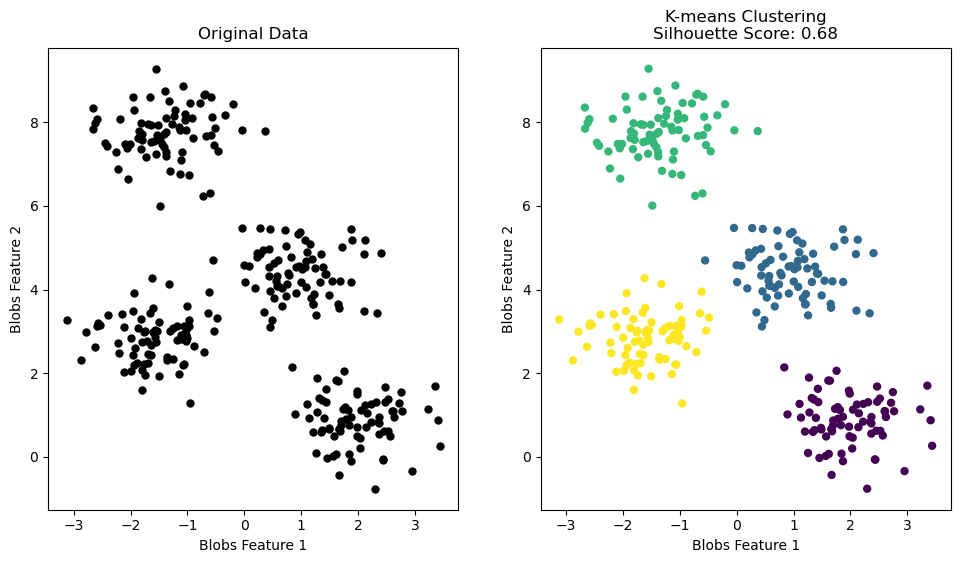

In [18]:
#Plot the original data
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.scatter(X['Feature 1'], X['Feature 2'], c='k', s=25)
#plt.scatter(X['Feature 1'], X['Feature 2'], c=y, cmap='viridis', s=25)
plt.xlabel('Blobs Feature 1')
plt.ylabel('Blobs Feature 2')
plt.title("Original Data")

#Plot the K-means clustering results
plt.subplot(1, 3, 2)
plt.scatter(X['Feature 1'], X['Feature 2'], c=kmeans_labels, cmap='viridis', s=25)
plt.xlabel('Blobs Feature 1')
plt.ylabel('Blobs Feature 2')
plt.title(f"K-means Clustering\nSilhouette Score: {kmeans_silhouette:.2f}")
plt.show()

## Scikit Learn `load_wine`

In [24]:
#First step is to load the data into an oject and setup our X and y (not used in our learning)
wineData = load_wine()
#print(wineData.DESCR)

X = pd.DataFrame(wineData.data, columns=wineData.feature_names)
#y = pd.Series(wineData.target)
X.head()

#Using the shape command, you can investigate the dimensionality
print('Shape of Data (X):',wineData.data.shape)
#print('Shape of Target Data (y)', wineData.target.shape)

Shape of Data (X): (178, 13)


In [25]:
#Reduce dimensionality to 2D using PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

#Initialize the model object and train (or fit) the data
#Notice we are doing our predictions at the same time
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

In [26]:
#Calculate silhouette score for K-means
#Only since we have labels, gives us an idea of how the clustering results
kmeans_silhouette = silhouette_score(X, kmeans_labels)
print(kmeans_silhouette)

0.6568536504294317


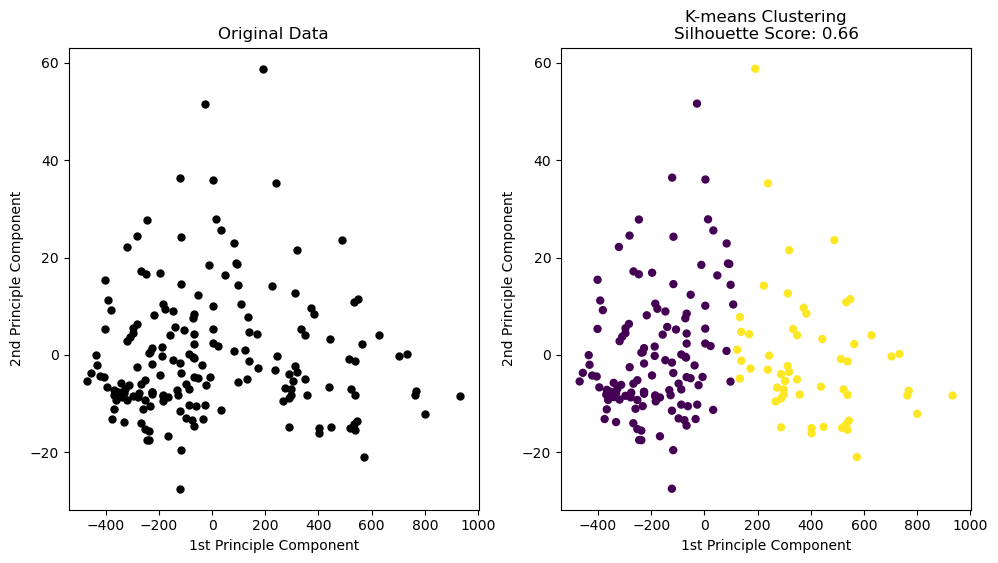

In [27]:
#Plot the original data
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c='k', s=25)
#plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=25)
plt.xlabel('1st Principle Component')
plt.ylabel('2nd Principle Component')
plt.title("Original Data")

#Plot the K-means clustering results
plt.subplot(1, 3, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=25)
plt.title("K-means Clustering")
plt.xlabel('1st Principle Component')
plt.ylabel('2nd Principle Component')
plt.title(f"K-means Clustering\nSilhouette Score: {kmeans_silhouette:.2f}")

plt.show()

In [28]:
kmeans_labels

array([1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0], dtype=int32)

## Gaussian Mixture Model

In [29]:
#Example of supress warnings for Numpy version out of range (optional)
import warnings
warnings.filterwarnings("ignore", category=Warning)

#Pull in the libraries we need
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.datasets import load_wine

#New libraries for access to model selection tasks
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt
%matplotlib inline

In [30]:
#First step is to generate synthetic data and setup our X and y (not used in our learning)
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
X = pd.DataFrame(X, columns=['Feature 1', 'Feature 2'])
X.head()

,Feature 1,Feature 2
0,0.836857,2.136359
1,-1.413658,7.409623
2,1.155213,5.099619
3,-1.018616,7.814915
4,1.271351,1.892542


In [31]:
#Initialize the model object and train (or fit) the data
#Notice we are doing our predictions at the same time
gmm = GaussianMixture(n_components=4, random_state=42)
gmm_labels = gmm.fit_predict(X)

In [32]:
#Calculate silhouette score for GMM
gmm_silhouette = silhouette_score(X, gmm_labels)
print(gmm_silhouette)

0.6819938690643478


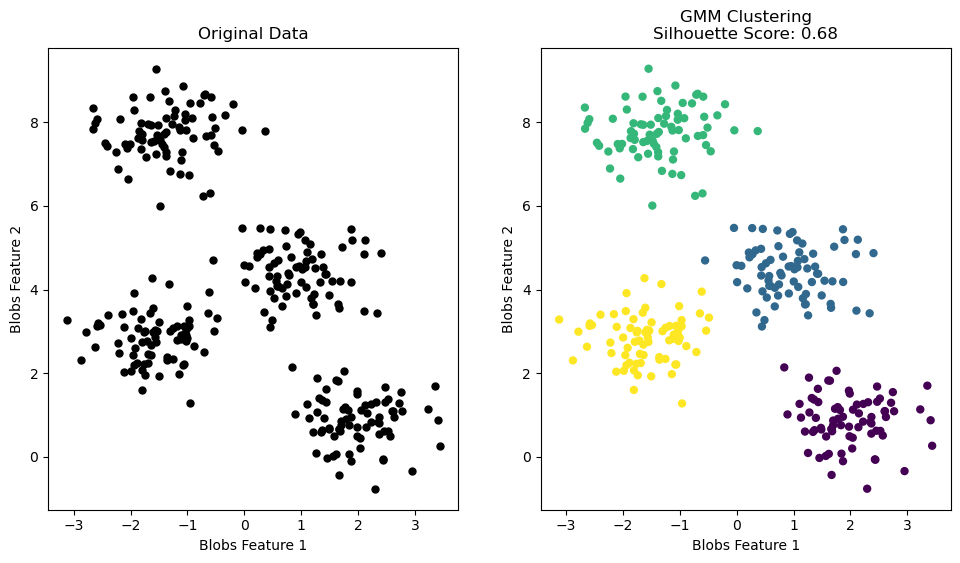

In [33]:
#Plot the original data
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.scatter(X['Feature 1'], X['Feature 2'], c='k', s=25)
#plt.scatter(X['Feature 1'], X['Feature 2'], c=y, cmap='viridis', s=25)
plt.xlabel('Blobs Feature 1')
plt.ylabel('Blobs Feature 2')
plt.title("Original Data")

#Plot the GMM clustering results
plt.subplot(1, 3, 2)
plt.scatter(X['Feature 1'], X['Feature 2'], c=gmm_labels, cmap='viridis', s=25)
plt.xlabel('Blobs Feature 1')
plt.ylabel('Blobs Feature 2')
plt.title(f"GMM Clustering\nSilhouette Score: {gmm_silhouette:.2f}")

plt.show()

In [34]:
#First step is to load the data into an oject and setup our X and y (not used in our learning)
wineData = load_wine()
#print(wineData.DESCR)

X = pd.DataFrame(wineData.data, columns=wineData.feature_names)
#y = pd.Series(wineData.target)
X.head()

#Using the shape command, you can investigate the dimensionality
#print('Shape of Data (X):',wineData.data.shape)
#print('Shape of Target Data (y)', wineData.target.shape)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [35]:
#Reduce dimensionality to 2D using PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

#Initialize the model object and train (or fit) the data
#Notice we are doing our predictions at the same time
gmm = GaussianMixture(n_components=2, random_state=42)
gmm_labels = gmm.fit_predict(X)

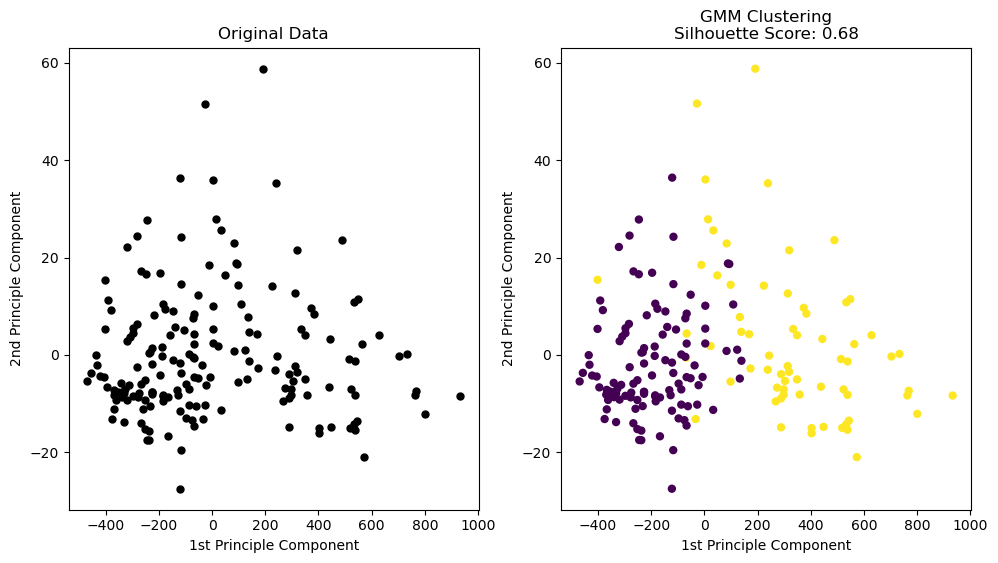

In [36]:
#Plot the original data
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c='k', s=25)
#plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', s=25)
plt.xlabel('1st Principle Component')
plt.ylabel('2nd Principle Component')
plt.title("Original Data")

#Plot the GMM clustering results
plt.subplot(1, 3, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='viridis', s=25)
plt.title("GMM Clustering")
plt.xlabel('1st Principle Component')
plt.ylabel('2nd Principle Component')
plt.title(f"GMM Clustering\nSilhouette Score: {gmm_silhouette:.2f}")

plt.show()